# 6. Analiza falkowa jako proces filtracji

**Arkadiusz Liber** · *Falki w praktyce. Od wzoru do kodu*

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/writingin/falki-w-praktyce-od-wzoru-do-kodu-notatniki/blob/main/rozdzial-06.ipynb)

Notatnik do książki. Zawiera wszystkie programy z tekstu rozdziału oraz ćwiczenia z rozwiązaniami.

Notatnik działa lokalnie (Jupyter) i w Google Colab. Komórki można uruchamiać po kolei poleceniem *Uruchom wszystko*.

In [1]:
# Uruchom tę komórkę jako pierwszą (lokalnie albo w Google Colab).
import sys, subprocess, importlib.util, os
if importlib.util.find_spec("pywt") is None:      # PyWavelets
    subprocess.check_call([sys.executable, "-m", "pip",
                           "install", "-q", "PyWavelets"])
import numpy as np
import matplotlib.pyplot as plt
import pywt

SZARY, NIEBIESKI, RDZAWY, ZIELONY = "#757575", "#1273E2", "#D93B0B", "#078832"
FIOLET, BURSZTYN = "#9258D5", "#B36000"
plt.rcParams.update({
    "text.color": SZARY, "axes.labelcolor": SZARY, "axes.edgecolor": SZARY,
    "xtick.color": SZARY, "ytick.color": SZARY, "axes.titlecolor": SZARY,
    "font.size": 10, "axes.titlesize": 10,
    "axes.spines.top": False, "axes.spines.right": False})


## Programy z tekstu rozdziału

### Kod 6.1. Splot i charakterystyki częstotliwościowe filtrów Haara

In [2]:
import numpy as np

h = np.array([1, 1])/np.sqrt(2)      # filtr dolnoprzepustowy
g = np.array([1, -1])/np.sqrt(2)     # filtr górnoprzepustowy

x = np.array([4., 6, 10, 12, 8, 6, 5, 5])
print(np.convolve(x, h).round(3))    # splot, wzór (6.1)
print(np.convolve(x, g).round(3))

def charakterystyka(filtr, omega):
    """Charakterystyka częstotliwościowa, wzór (6.2)."""
    n = np.arange(len(filtr))
    return np.exp(-1j*np.outer(omega, n)) @ filtr

omega = np.array([0, np.pi/2, np.pi])
print(np.abs(charakterystyka(h, omega)).round(3))
print(np.abs(charakterystyka(g, omega)).round(3))

[ 2.828  7.071 11.314 15.556 14.142  9.899  7.778  7.071  3.536]
[ 2.828  1.414  2.828  1.414 -2.828 -1.414 -0.707  0.    -3.536]
[1.414 1.    0.   ]
[0.    1.    1.414]


### Kod 6.2. Decymacja i ekspansja

In [3]:
import numpy as np

def decymacja(x):
    return x[::2]

def ekspansja(x):
    y = np.zeros(2*len(x))
    y[::2] = x
    return y

v = np.array([1., 2, 2, 4, 3, 2, 1, 2])
print(ekspansja(v))
print(decymacja(ekspansja(v)))       # odtwarza v
print(ekspansja(decymacja(v)))       # nie odtwarza v

[1. 0. 2. 0. 2. 0. 4. 0. 3. 0. 2. 0. 1. 0. 2. 0.]
[1. 2. 2. 4. 3. 2. 1. 2.]
[1. 0. 2. 0. 3. 0. 1. 0.]


### Kod 6.3. Własności filtrów ortogonalnych

In [4]:
import numpy as np
import pywt

for nazwa in ("haar", "db2", "db4", "sym8"):
    w = pywt.Wavelet(nazwa)
    h, g = np.array(w.rec_lo), np.array(w.rec_hi)
    L = len(h)
    n = np.arange(L)
    suma = np.isclose(h.sum(), np.sqrt(2))
    ortog = all(np.isclose(h[:L - 2*k] @ h[2*k:], float(k == 0))
                for k in range(L//2))               # wzór (6.9)
    lustro = np.allclose(g, (-1)**n*h[::-1])         # wzór (6.10)
    odwr = np.allclose(w.dec_lo, h[::-1])
    om = np.linspace(0, np.pi, 5)
    H = lambda o: np.abs(np.exp(-1j*np.outer(o, n)) @ h)
    moc = np.allclose(H(om)**2 + H(om + np.pi)**2, 2)  # wzór (6.11)
    print(nazwa, L, suma, ortog, lustro, odwr, moc)

haar 2 True True True True True
db2 4 True True True True True
db4 8 True True True True True
sym8 16 True True True True True


### Kod 6.4. Jeden stopień transformaty zbudowany ze splotu, decymacji i ekspansji

In [5]:
import numpy as np
import pywt

w = pywt.Wavelet("db2")
L = w.dec_len
rng = np.random.default_rng(3)
x = rng.normal(size=32)

# analiza: filtrowanie i decymacja
cA = np.convolve(x, w.dec_lo)[1::2]
cD = np.convolve(x, w.dec_hi)[1::2]
cA_pywt, cD_pywt = pywt.dwt(x, w, mode="zero")
print(np.allclose(cA, cA_pywt), np.allclose(cD, cD_pywt))
print(len(x), len(cA), len(cD))

# synteza: ekspansja, filtrowanie, sumowanie
def ekspansja(c):
    y = np.zeros(2*len(c))
    y[::2] = c
    return y

y = (np.convolve(ekspansja(cA), w.rec_lo)
     + np.convolve(ekspansja(cD), w.rec_hi))
y = y[L - 2:L - 2 + len(x)]           # usunięcie opóźnienia filtrów
print(np.allclose(y, x))

True True
32 17 17
True


### Kod 6.5. Szybka transformata falkowa: własna implementacja drzewa filtrów

In [6]:
import numpy as np
import pywt

def analiza(x, w):
    return (np.convolve(x, w.dec_lo)[1::2],
            np.convolve(x, w.dec_hi)[1::2])

def synteza(cA, cD, w, n):
    def eksp(c):
        y = np.zeros(2*len(c)); y[::2] = c
        return y
    y = (np.convolve(eksp(cA), w.rec_lo)
         + np.convolve(eksp(cD), w.rec_hi))
    return y[w.dec_len - 2:w.dec_len - 2 + n]

def transformata(x, w, poziomy):
    wsp, dlugosci = [], []
    for _ in range(poziomy):
        dlugosci.append(len(x))
        x, d = analiza(x, w)
        wsp.insert(0, d)
    return [x] + wsp, dlugosci

def odwrotna(wsp, w, dlugosci):
    x = wsp[0]
    for d, n in zip(wsp[1:], reversed(dlugosci)):
        x = synteza(x, d, w, n)
    return x

w = pywt.Wavelet("db4")
rng = np.random.default_rng(5)
s = rng.normal(size=500)
wsp, dl = transformata(s, w, 3)
wzorzec = pywt.wavedec(s, w, mode="zero", level=3)
print(all(np.allclose(a, b) for a, b in zip(wsp, wzorzec)))
print([len(c) for c in wsp])
print(np.allclose(odwrotna(wsp, w, dl), s))

True
[68, 68, 130, 253]
True


### Kod 6.6. Składowe sygnału odtworzone z poszczególnych poziomów

In [7]:
import numpy as np
import pywt

t = np.linspace(0, 1, 512, endpoint=False)
s = np.sin(2*np.pi*3*t) + 0.3*np.sign(np.sin(2*np.pi*40*t))

wsp = pywt.wavedec(s, "sym4", level=3, mode="periodization")
skladowe = []
for i in range(len(wsp)):
    tylko_jeden = [c if k == i else np.zeros_like(c)
                   for k, c in enumerate(wsp)]
    skladowe.append(pywt.waverec(tylko_jeden, "sym4",
                                 mode="periodization"))
A3, D3, D2, D1 = skladowe
print(np.allclose(A3 + D3 + D2 + D1, s))        # wzór (6.12)
print([round(float(np.sum(c**2)), 2) for c in skladowe],
      round(float(np.sum(s**2)), 2))

True
[260.85, 30.17, 5.36, 4.76] 301.14


### Kod 6.7. Dekompozycja pakietowa sygnału o dwóch bliskich wysokich częstotliwościach

In [8]:
import numpy as np
import pywt

fs = 1024
t = np.arange(fs)/fs
s = np.sin(2*np.pi*300*t) + np.sin(2*np.pi*420*t)

# zwykła DWT: obie składowe trafiają do cD1 (256–512 Hz)
wsp = pywt.wavedec(s, "db8", level=3, mode="periodization")
for nazwa, c in zip(["cA3", "cD3", "cD2", "cD1"], wsp):
    print(nazwa, round(float(np.sum(c**2)), 1))

# pakiety: osiem pasm o szerokości 64 Hz
wp = pywt.WaveletPacket(s, "db8", mode="periodization", maxlevel=3)
for i, wezel in enumerate(wp.get_level(3, order="freq")):
    print(f"{wezel.path}  {64*i:3d}–{64*(i + 1):3d} Hz  "
          f"energia {np.sum(wezel.data**2):6.1f}")

cA3 0.0
cD3 0.0
cD2 72.9
cD1 951.1
aaa    0– 64 Hz  energia    0.0
aad   64–128 Hz  energia    0.0
add  128–192 Hz  energia    1.8
ada  192–256 Hz  energia   71.1
dda  256–320 Hz  energia  428.6
ddd  320–384 Hz  energia   30.2
dad  384–448 Hz  energia  491.2
daa  448–512 Hz  energia    1.2


### Kod 6.8. Wybór najlepszej bazy pakietowej według kryterium entropii

In [9]:
import numpy as np
import pywt

def entropia(c):
    p = c[c != 0]**2
    return float(-np.sum(p*np.log(p)))

def najlepsza_baza(wp, sciezka=""):
    """Zwraca (koszt, lista węzłów) dla poddrzewa o danym korzeniu."""
    wezel = wp[sciezka] if sciezka else wp
    koszt = entropia(wezel.data)
    if len(sciezka) == wp.maxlevel:
        return koszt, [sciezka]
    ka, ba = najlepsza_baza(wp, sciezka + "a")
    kd, bd = najlepsza_baza(wp, sciezka + "d")
    if ka + kd < koszt:
        return ka + kd, ba + bd
    return koszt, [sciezka]

fs = 1024
t = np.arange(fs)/fs
s = np.sin(2*np.pi*20*t) + np.sin(2*np.pi*416*t)*(t < 0.5)
s /= np.linalg.norm(s)                        # energia równa 1

wp = pywt.WaveletPacket(s, "db8", mode="periodization", maxlevel=4)
koszt, baza = najlepsza_baza(wp)
print("najlepsza baza:", baza, "koszt:", round(koszt, 3))

dwt = ["aaaa", "aaad", "aad", "ad", "d"]
print("koszt bazy DWT:",
      round(sum(entropia(wp[p].data) for p in dwt), 3))
pelna = [w.path for w in wp.get_level(4)]
print("koszt pełnej dekompozycji:",
      round(sum(entropia(wp[p].data) for p in pelna), 3))

najlepsza baza: ['aaaa', 'aaad', 'aad', 'ad', 'daa', 'dada', 'dadd', 'dda', 'ddd'] koszt: 4.51
koszt bazy DWT: 4.981
koszt pełnej dekompozycji: 4.523


## Ćwiczenia i rozwiązania

### Ćwiczenie 6.1
Wyznacz charakterystykę amplitudową filtru średniej ruchomej z trzech próbek, h = (1/3, 1/3, 1/3). Dla jakiej pulsacji filtr całkowicie tłumi sygnał?

### Rozwiązanie 6.1

zgodność ze wzorem |1 + 2 cos ω|/3: True
zero charakterystyki: ω = 2.0944  2π/3 = 2.0944


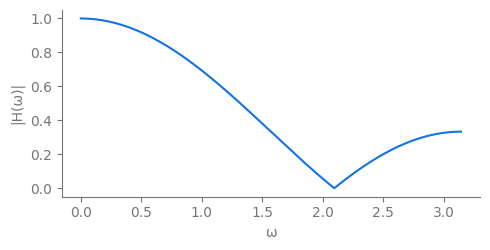

In [10]:
h = np.ones(3)/3
omega = np.linspace(0, np.pi, 3001)
H = np.abs(np.exp(-1j*np.outer(omega, np.arange(3))) @ h)
print("zgodność ze wzorem |1 + 2 cos ω|/3:",
      np.allclose(H, np.abs(1 + 2*np.cos(omega))/3))
print("zero charakterystyki: ω =", round(omega[np.argmin(H)], 4),
      " 2π/3 =", round(2*np.pi/3, 4))
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.plot(omega, H, color=NIEBIESKI); ax.set_xlabel("ω"); ax.set_ylabel("|H(ω)|")
plt.tight_layout(); plt.show()

### Ćwiczenie 6.2
Sprawdź, że filtry (6.3) spełniają warunki (6.9)–(6.11).

### Rozwiązanie 6.2

In [11]:
h = np.array([1, 1])/np.sqrt(2)
g = np.array([1, -1])/np.sqrt(2)
print("suma:", np.isclose(h.sum(), np.sqrt(2)), " energia:", np.isclose(h @ h, 1))
print("wzór (6.10):", np.allclose(g, (-1)**np.arange(2)*h[::-1]))
om = np.linspace(0, np.pi, 9)
H = lambda f, o: np.abs(np.exp(-1j*np.outer(o, np.arange(2))) @ f)
print("wzór (6.11):", np.allclose(H(h, om)**2 + H(h, om + np.pi)**2, 2),
      np.allclose(H(g, om), H(h, om + np.pi)))

suma: True  energia: True
wzór (6.10): True
wzór (6.11): True True


### Ćwiczenie 6.3
Dla wektora (1, 2, 3, 4, 5, 6) wykonaj kolejno decymację i ekspansję oraz ekspansję i decymację. Porównaj wyniki.

### Rozwiązanie 6.3

In [12]:
def ekspansja(x):
    y = np.zeros(2*len(x)); y[::2] = x
    return y
v = np.arange(1., 7)
print(ekspansja(v[::2]))
print(ekspansja(v)[::2])

[1. 0. 3. 0. 5. 0.]
[1. 2. 3. 4. 5. 6.]


### Ćwiczenie 6.4
Wyznacz filtr górnoprzepustowy ze wzoru (6.10) dla filtru h falki db2 i porównaj go z `rec_hi` z biblioteki PyWavelets.

### Rozwiązanie 6.4

In [13]:
w = pywt.Wavelet("db2")
h = np.array(w.rec_lo)
g = (-1)**np.arange(len(h))*h[::-1]
print(g.round(6)); print(np.array(w.rec_hi).round(6))
# postać dokładna filtru db2
r3 = np.sqrt(3)
print(np.allclose(h, np.array([1 + r3, 3 + r3, 3 - r3, 1 - r3])/(4*np.sqrt(2))))

[-0.12941  -0.224144  0.836516 -0.482963]
[-0.12941  -0.224144  0.836516 -0.482963]
True


### Ćwiczenie 6.5
Korzystając z kodu 6.4, sprawdź, że stopień analizy zachowuje energię sygnału. Dlaczego w trybie `zero` równość jest dokładna, a w trybie `symmetric` nie?

### Rozwiązanie 6.5

In [14]:
rng = np.random.default_rng(3)
x = rng.normal(size=32)
for tryb in ("zero", "periodization", "symmetric"):
    cA, cD = pywt.dwt(x, "db2", mode=tryb)
    print(f"{tryb:14s} {np.sum(x**2):.6f} {np.sum(cA**2) + np.sum(cD**2):.6f}")
# W trybie zero transformowany jest sygnał uzupełniony zerami (ta sama energia),
# w trybie periodization transformata jest ortogonalna w R^N.
# W trybie symmetric sygnał jest przedłużany lustrzanymi kopiami próbek
# brzegowych, które wnoszą dodatkową energię do współczynników.

zero           39.603850 39.603850
periodization  39.603850 39.603850
symmetric      39.603850 39.879938


### Ćwiczenie 6.6
Pokaż, że filtr h = (1/2, 1/2) z filtrem g = (1/2, −1/2) nie daje przekształcenia ortogonalnego. Jak trzeba zmienić filtry syntezy, aby mimo to odtworzyć sygnał?

### Rozwiązanie 6.6

In [15]:
x = np.array([4., 6, 10, 12, 8, 6, 5, 5])
c = (x[0::2] + x[1::2])/2          # średnie
d = (x[0::2] - x[1::2])/2          # połowy różnic
print("energia:", np.sum(x**2), "→", np.sum(c**2) + np.sum(d**2))
y = np.empty_like(x)
y[0::2] = c + d                    # synteza filtrami (1, 1) i (1, −1)
y[1::2] = c - d
print(np.allclose(y, x))

energia: 446.0 → 223.0
True


### Ćwiczenie 6.7
Wykonaj dekompozycję pakietową sygnału z kodu 6.7 na czterech poziomach. Jaka jest szerokość jednego pasma? W których pasmach leżą składowe?

### Rozwiązanie 6.7

ddad  288–320 Hz  energia 425.0
dadd  416–448 Hz  energia 383.7
dada  384–416 Hz  energia 107.5
adad  192–224 Hz  energia 70.5


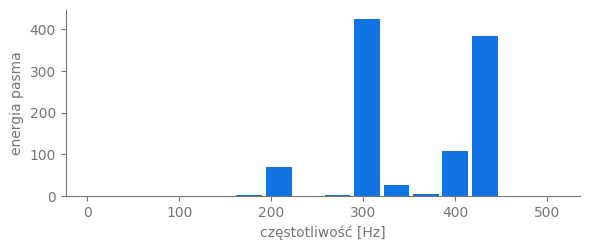

In [16]:
fs = 1024
t = np.arange(fs)/fs
s = np.sin(2*np.pi*300*t) + np.sin(2*np.pi*420*t)
wp = pywt.WaveletPacket(s, "db8", mode="periodization", maxlevel=4)
wezly = wp.get_level(4, order="freq")
energie = np.array([np.sum(w.data**2) for w in wezly])
for i in np.argsort(energie)[::-1][:4]:
    print(f"{wezly[i].path}  {32*i}–{32*(i + 1)} Hz  energia {energie[i]:.1f}")
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.bar(32*np.arange(16) + 16, energie, width=28, color=NIEBIESKI)
ax.set_xlabel("częstotliwość [Hz]"); ax.set_ylabel("energia pasma")
plt.tight_layout(); plt.show()

### Ćwiczenie 6.8
Wyznacz najlepszą bazę pakietową dla sygnału złożonego z samego impulsu jednostkowego oraz dla samej sinusoidy. Zinterpretuj różnicę.

### Rozwiązanie 6.8

In [17]:
def entropia(c):
    p = c[c != 0]**2
    return float(-np.sum(p*np.log(p)))

def najlepsza_baza(wp, sciezka=""):
    wezel = wp[sciezka] if sciezka else wp
    koszt = entropia(wezel.data)
    if len(sciezka) == wp.maxlevel:
        return koszt, [sciezka]
    ka, ba = najlepsza_baza(wp, sciezka + "a")
    kd, bd = najlepsza_baza(wp, sciezka + "d")
    return (ka + kd, ba + bd) if ka + kd < koszt else (koszt, [sciezka])

impuls = np.zeros(1024); impuls[300] = 1
sinus = np.sin(2*np.pi*200*np.arange(1024)/1024)
sinus /= np.linalg.norm(sinus)
for nazwa, s in (("impuls", impuls), ("sinusoida", sinus)):
    wp = pywt.WaveletPacket(s, "db8", mode="periodization", maxlevel=4)
    koszt, baza = najlepsza_baza(wp)
    print(nazwa, "→", baza if baza != [""] else "bez dekompozycji",
          " koszt:", round(koszt, 3))
# Impuls jest najlepiej skupiony w dziedzinie czasu: każda filtracja go rozmywa,
# więc najlepszą „bazą” są same próbki. Sinusoida jest skupiona w częstotliwości:
# opłaca się dzielić pasmo jak najdrobniej wokół jej częstotliwości.

impuls → bez dekompozycji  koszt: -0.0
sinusoida → ['aaaa', 'aaad', 'aada', 'aadd', 'adaa', 'adad', 'adda', 'addd', 'daaa', 'daad', 'dada', 'dadd', 'ddaa', 'ddad', 'ddda', 'dddd']  koszt: 4.682
